### 0.1 Data Loading & Exploration

In [2]:
#Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#To suppress all warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# 1. Load Titanic dataset
df = sns.load_dataset('titanic')

In [6]:
# 2. Display the first 10 rows
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [10]:
#3. Count missing values in each column
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [12]:
#4. Display column names
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [14]:
#5. Show unique values in the embarked column
df['embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

### 0.2 Data Cleaning

In [17]:
#1. Fill missing embarked with the most frequent value
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [19]:
#2. Convert sex and class to categorical type
df['sex'] = df['sex'].astype('category')
df['class'] = df['class'].astype('category')

In [21]:
#3. Create a new column family_size= sibsp + parch + 1
df['family_size'] = df['sibsp'] + df['parch'] + 1

In [23]:
#4. Cap fare at the 99th percentile to reduce outlier impact
upper_limit = df['fare'].quantile(0.99)
df['fare'] = df['fare'].clip(upper=upper_limit)

### 0.3 Visualization

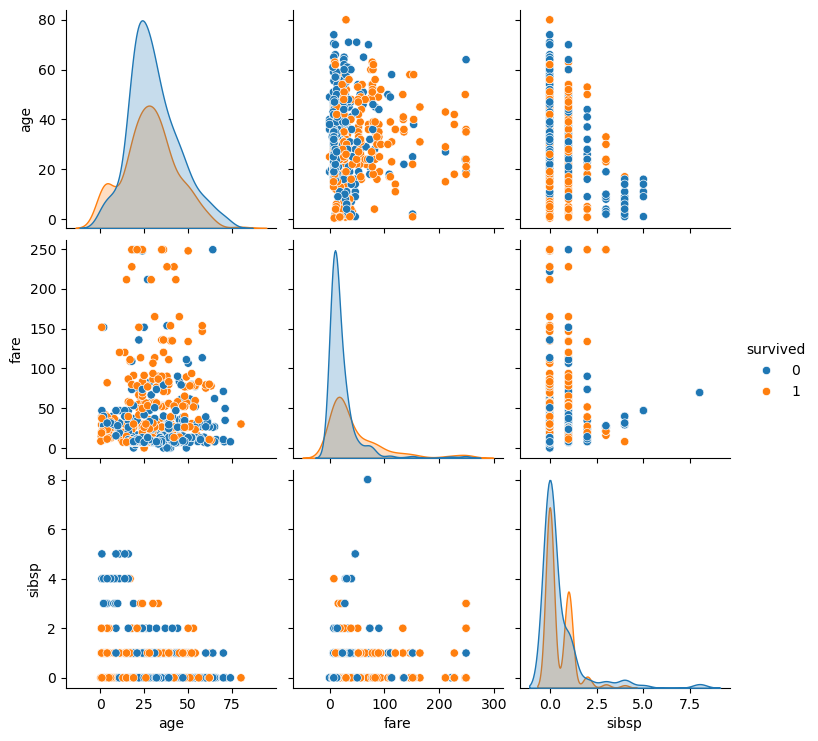

In [26]:
#1. Pairplot of ['age', 'fare', 'sibsp'] colored by survived
sns.pairplot(df, vars=['age', 'fare', 'sibsp'], hue='survived')
plt.show()

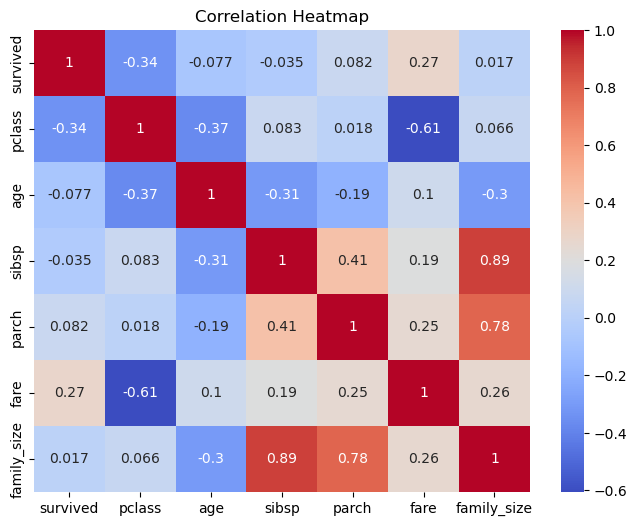

In [28]:
#2. Heatmap of correlations for numeric columns
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

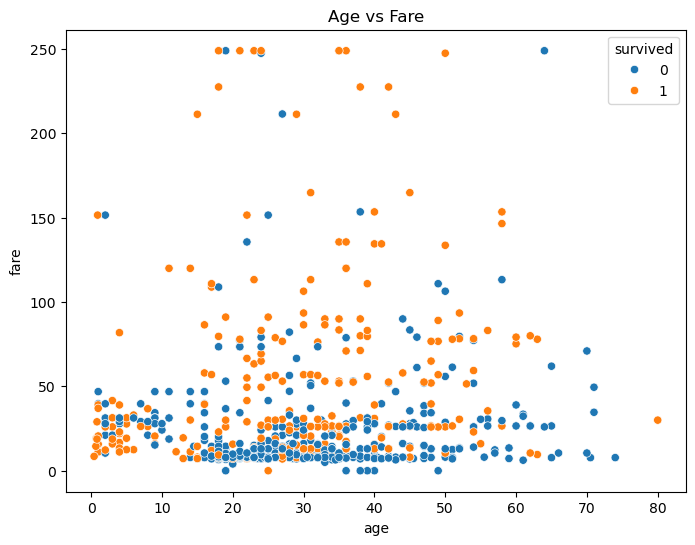

In [30]:
#3. Scatter plot of age vs fare, colored by survived
plt.figure(figsize=(8,6))
sns.scatterplot(x='age', y='fare', hue='survived', data=df)
plt.title('Age vs Fare')
plt.show()

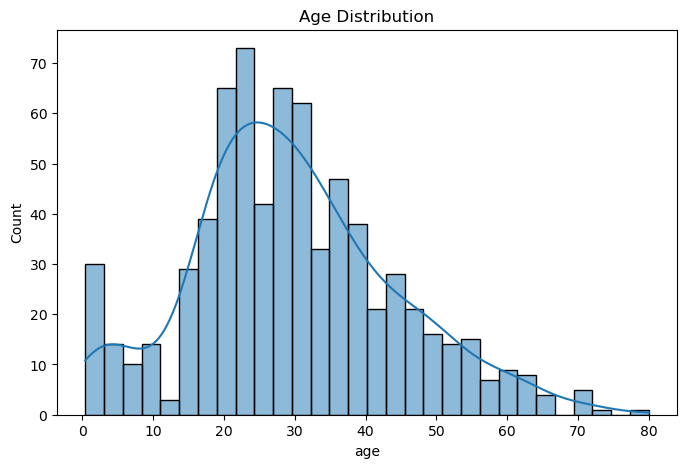

In [32]:
#4. Plot a histogram of age with 30 bins and KDE
plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.show()